# Chapitre 8 - Cours 3 : bagging, moyennage de modèles, stacking et bumping

Les deux premiers notebooks utilisaient le bootstrap pour **mesurer** l'incertitude. Ici
(sections 8.7 à 8.9 du livre), on s'en sert pour **améliorer** les prédictions :

1. le **bagging** (*bootstrap aggregating*) : moyenner un modèle réajusté sur des
   échantillons bootstrap (figures 8.9 à 8.12) ;
2. le **moyennage bayésien de modèles** et le **stacking** : combiner des modèles
   différents avec des poids bien choisis ;
3. le **bumping** : utiliser le bootstrap pour explorer l'espace des modèles et trouver
   un meilleur modèle unique (figure 8.13).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. Le bagging (section 8.7)

On dispose de données $Z = \{(x_1, y_1), \dots, (x_N, y_N)\}$ et d'une méthode qui
fournit une prédiction $\hat f(x)$. Pour chaque échantillon bootstrap $Z^{*b}$
($b = 1, \dots, B$), on réajuste la méthode, ce qui donne $\hat f^{*b}(x)$, puis on
moyenne :

$$\hat f_{\text{bag}}(x) = \frac1B\sum_{b=1}^B \hat f^{*b}(x). \qquad \text{(éq. (8.51))}$$

Si $\hat P$ désigne la loi empirique (masse $1/N$ sur chaque couple $(x_i, y_i)$), le
« vrai » estimateur bagging est $E_{\hat P}\hat f^*(x)$ ; (8.51) en est une
approximation de Monte-Carlo, qui converge quand $B \to \infty$.

> **Intuition.** Moyenner réduit la **variance** sans changer (beaucoup) le biais. Le
> bagging n'a d'intérêt que si $\hat f$ dépend de façon **non linéaire** ou
> **instable** des données : pour un lisseur linéaire, il ne change presque rien
> (exercice 8.4).

### Bagging d'un classifieur : votes ou probabilités ?

Pour un problème à $K$ classes, on associe au classifieur $\hat G(x)$ le vecteur
indicateur $\hat f(x)$ (un 1 à la classe prédite, des 0 ailleurs). Alors
$\hat f_{\text{bag}}(x) = (p_1(x), \dots, p_K(x))$ où $p_k(x)$ est la **proportion
d'arbres qui votent** pour la classe $k$, et le classifieur bagging est
$\hat G_{\text{bag}}(x) = \arg\max_k \hat f_{\text{bag}}(x)$ (**vote majoritaire**, ou
consensus).

Les proportions de votes **ne sont pas** des estimations des probabilités de classe : si
$\Pr(Y = 1\mid x) = 0{,}75$ et que tous les classifieurs prédisent 1, on obtient
$p_1(x) = 1$. Si le classifieur fournit lui-même des probabilités (pour un arbre : les
proportions de classes dans la feuille), on peut plutôt **moyenner ces probabilités**.

### Exemple : arbres sur données simulées (section 8.7.1)

* $N = 30$ observations, $p = 5$ variables gaussiennes centrées réduites, deux à deux
  corrélées à $0{,}95$ ;
* $\Pr(Y = 1\mid x_1 \le 0{,}5) = 0{,}2$ et $\Pr(Y = 1\mid x_1 > 0{,}5) = 0{,}8$ : le
  taux d'erreur de Bayes vaut $0{,}2$ ;
* un échantillon test de taille 2000.

Les arbres de classification sont étudiés au chapitre 9 ; leur construction (CART) étant
assez longue à coder, nous utilisons ici `DecisionTreeClassifier` de scikit-learn, sans
élagage, avec les règles d'arrêt par défaut de la fonction `tree` de R (un nœud n'est
coupé que s'il contient au moins 10 observations, chaque feuille en garde au moins 5) ;
les feuilles ne sont donc pas toujours pures, et leurs proportions de classes fournissent
des probabilités. Le **bagging**, lui, est codé à la main (`esl.ch08_inference`).

In [2]:
def simulate_trees_data(n, rng, p=5, rho=0.95):
    C = np.full((p, p), rho) + (1 - rho) * np.eye(p)
    X = rng.multivariate_normal(np.zeros(p), C, size=n)
    prob = np.where(X[:, 0] <= 0.5, 0.2, 0.8)
    return X, (rng.rand(n) < prob).astype(int)

X_tr, y_tr = simulate_trees_data(30, rng)
X_te, y_te = simulate_trees_data(2000, rng)
print("Proportion de Y = 1 (apprentissage, test) : %.2f, %.2f" % (y_tr.mean(), y_te.mean()))

Proportion de Y = 1 (apprentissage, test) : 0.47, 0.40


In [3]:
def fit_tree(Xb, yb, seed=0):
    return DecisionTreeClassifier(min_samples_split=10, min_samples_leaf=5,
                                  random_state=seed).fit(Xb, yb)

def tree_proba(tree, X):
    """Probabilités des classes 0 et 1 (même si l'échantillon n'a qu'une classe)."""
    P = np.zeros((len(X), 2))
    P[:, tree.classes_] = tree.predict_proba(X)
    return P

orig_tree = fit_tree(X_tr, y_tr)
err_orig = np.mean(orig_tree.predict(X_te) != y_te)
print("Erreur test de l'arbre original : %.3f" % err_orig)

Erreur test de l'arbre original : 0.295


**Figure 8.9.** L'arbre original et onze arbres construits sur des échantillons
bootstrap (seule la première coupure est dessinée ; chaque nœud indique son effectif et
la répartition [classe 0, classe 1]). Les variables de coupure et
les seuils changent d'un arbre à l'autre : à cause de la forte corrélation entre
variables, les arbres sont très **instables**.

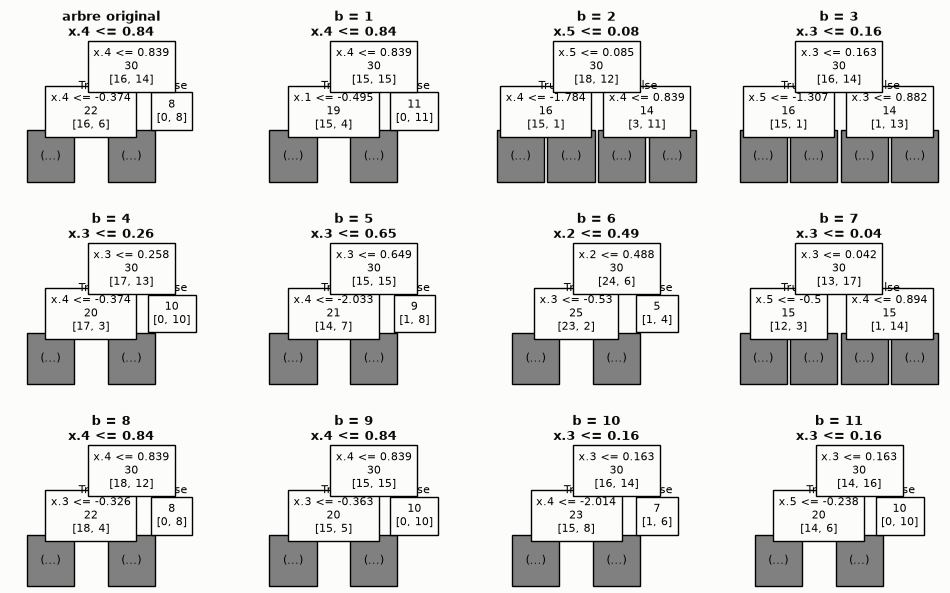

In [4]:
boot_idx = inf.bootstrap_indices(30, 11, rng)
trees_fig = [orig_tree] + [fit_tree(X_tr[i], y_tr[i]) for i in boot_idx]
fig, axes = plt.subplots(3, 4, figsize=(12, 7))
names = ["x.%d" % (j + 1) for j in range(5)]
for k, (a, t) in enumerate(zip(axes.ravel(), trees_fig)):
    plot_tree(t, max_depth=1, feature_names=names, impurity=False, label="none",
              filled=False, ax=a, fontsize=8, proportion=False)
    j, s = t.tree_.feature[0], t.tree_.threshold[0]
    a.set_title(("arbre original" if k == 0 else "b = %d" % k)
                + "\n%s <= %.2f" % (names[j], s), fontsize=9)
fig.subplots_adjust(hspace=0.5)
plt.show()

### Erreur test en fonction du nombre d'arbres (figure 8.10)

On construit 200 arbres bootstrap et l'on calcule, pour $b = 1, \dots, 200$, l'erreur
test du bagging des $b$ premiers arbres, par **vote** et par **moyenne des
probabilités**.

In [5]:
def tree_fit_proba(Xb, yb, Xe):
    return tree_proba(fit_tree(Xb, yb), Xe)

probas = inf.bootstrap_predictions(tree_fit_proba, X_tr, y_tr, X_te, 200, rng)
err_vote, err_prob = inf.bagging_error_curves(probas, y_te)
print("Après 200 arbres : vote %.3f, probabilités %.3f, arbre seul %.3f"
      % (err_vote[-1], err_prob[-1], err_orig))

Après 200 arbres : vote 0.263, probabilités 0.265, arbre seul 0.295


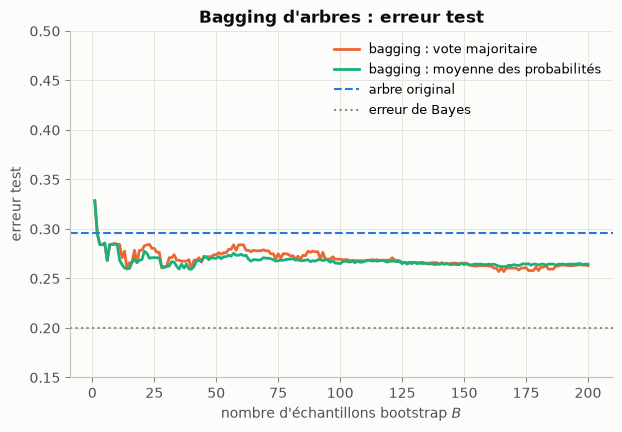

In [6]:
bs = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(bs, err_vote, color=ORANGE, label="bagging : vote majoritaire")
ax.plot(bs, err_prob, color=COLORS[2], label="bagging : moyenne des probabilités")
ax.axhline(err_orig, color=BLUE, ls="--", lw=1.5, label="arbre original")
ax.axhline(0.2, color=GRAY, ls=":", lw=1.5, label="erreur de Bayes")
ax.set(title="Bagging d'arbres : erreur test", xlabel="nombre d'échantillons bootstrap $B$",
       ylabel="erreur test", ylim=(0.15, 0.5))
ax.legend()
plt.show()

Une seule courbe dépend beaucoup de l'échantillon d'apprentissage tiré. Moyennons
l'expérience sur 20 échantillons d'apprentissage indépendants.

In [7]:
R, Bmax = 20, 100
E_orig, E_vote, E_prob = [], [], []
for r in range(R):
    Xr, yr = simulate_trees_data(30, rng)
    E_orig.append(np.mean(fit_tree(Xr, yr).predict(X_te) != y_te))
    pr = inf.bootstrap_predictions(tree_fit_proba, Xr, yr, X_te, Bmax, rng)
    ev, ep = inf.bagging_error_curves(pr, y_te)
    E_vote.append(ev); E_prob.append(ep)
E_vote, E_prob = np.mean(E_vote, 0), np.mean(E_prob, 0)

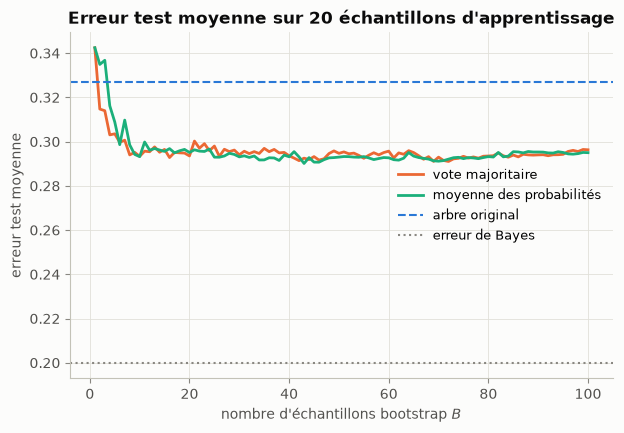

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, Bmax + 1), E_vote, color=ORANGE, label="vote majoritaire")
ax.plot(np.arange(1, Bmax + 1), E_prob, color=COLORS[2], label="moyenne des probabilités")
ax.axhline(np.mean(E_orig), color=BLUE, ls="--", lw=1.5, label="arbre original")
ax.axhline(0.2, color=GRAY, ls=":", lw=1.5, label="erreur de Bayes")
ax.set(title="Erreur test moyenne sur 20 échantillons d'apprentissage",
       xlabel="nombre d'échantillons bootstrap $B$", ylabel="erreur test moyenne")
ax.legend()
plt.show()

En moyenne, le bagging réduit l'erreur de l'arbre seul de plusieurs points, l'essentiel
du gain étant acquis dès quelques dizaines d'arbres ; vote et moyenne des probabilités
donnent ici des résultats voisins. L'erreur reste loin de l'erreur de Bayes : avec
seulement 30 observations, les arbres sont très instables, et la forte corrélation entre
variables les fait souvent couper sur $x_2, \dots, x_5$ plutôt que sur $x_1$.

### Pourquoi le bagging aide en perte quadratique

Soit $P$ la loi (inconnue) des données et l'agrégat « idéal »
$f_{\text{ag}}(x) = E_P\hat f^*(x)$, où $\hat f^*$ est ajusté sur un échantillon tiré
**selon $P$** (et non selon $\hat P$). Pour $x$ fixé, en insérant $f_{\text{ag}}(x)$ :

$$\begin{aligned}
E_P[Y - \hat f^*(x)]^2 &= E_P[Y - f_{\text{ag}}(x) + f_{\text{ag}}(x) - \hat f^*(x)]^2 \\
&= E_P[Y - f_{\text{ag}}(x)]^2 + E_P[\hat f^*(x) - f_{\text{ag}}(x)]^2
   \ge E_P[Y - f_{\text{ag}}(x)]^2. \qquad \text{(éq. (8.52))}
\end{aligned}$$

Le double produit est nul car $Y$ (nouvelle observation) est indépendant de $\hat f^*$ et
$E_P[\hat f^*(x) - f_{\text{ag}}(x)] = 0$ par définition de $f_{\text{ag}}$. L'écart est
exactement la **variance** de $\hat f^*(x)$ : l'agrégation sur la population ne dégrade
jamais l'erreur quadratique. Le bagging, qui tire dans $\hat P$ au lieu de $P$, en est une
approximation.

Vérifions-le sur un arbre de régression (profond, donc très variable) : pour
$f(x) = \sin(4x)$, $x \sim \mathcal U[0,1]$, $\sigma = 0{,}5$, $N = 50$, on estime biais et
variance en chaque point d'une grille sur 100 échantillons d'apprentissage.

In [ ]:
f_reg = lambda t: np.sin(4 * t)
xg = np.linspace(0.02, 0.98, 60)[:, None]
def reg_tree(Xb, yb, Xe):
    return DecisionTreeRegressor(min_samples_leaf=2, random_state=0).fit(Xb, yb).predict(Xe)
single, bagged = [], []
for r in range(100):
    xr = rng.rand(50, 1); yr = f_reg(xr[:, 0]) + 0.5 * rng.randn(50)
    single.append(reg_tree(xr, yr, xg))
    bagged.append(inf.bootstrap_predictions(reg_tree, xr, yr, xg, 30, rng).mean(0))
single, bagged = np.array(single), np.array(bagged)
for name, P in [("arbre seul", single), ("arbre baggé", bagged)]:
    print("%-12s biais^2 moyen = %.4f   variance moyenne = %.4f"
          % (name, np.mean((P.mean(0) - f_reg(xg[:, 0])) ** 2), np.mean(P.var(0))))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, P, t in [(ax[0], single, "Arbre de régression seul"), (ax[1], bagged, "Arbre baggé ($B=30$)")]:
    for r in range(8):
        a.plot(xg[:, 0], P[r], color=BLUE, lw=1, alpha=0.6)
    a.plot(xg[:, 0], f_reg(xg[:, 0]), color=ORANGE, lw=2, label="vraie fonction")
    a.set(title=t, xlabel="$x$")
    a.legend(loc="lower left")
ax[0].set_ylabel(r"$\hat f(x)$")
plt.show()